# Pipeline de dados — do bruto ao lote pronto para o modelo

Complementa a EDA (`01_eda_xbd.ipynb`). Aqui o objetivo e mostrar, com testes que
falham se algo estiver errado, que:

1. o manifesto e o split que o treino usa sao o mesmo conjunto;
2. nenhuma cena nem duplicata atravessa os splits;
3. o pre-processamento de validacao/teste e deterministico;
4. o aumento de dados so atua no treino e a mascara acompanha as transformacoes geometricas;
5. o DataLoader entrega lotes com o shape e os valores esperados;
6. a seed reproduz split e amostras.

Pre-requisitos (uma vez, nesta ordem): `scripts/build_index.py` (gera `cache/`),
`python -m xbd.prep` (gera `data/`) e `scripts/gerar_manifesto.py` (gera `manifestos/`).

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
import xbd_viz as V
from xbd.config import from_preset, IGNORE_INDEX
from xbd.splits import montar_splits
from xbd.data import Aug, XBDDataset, build_loaders, XBD_TREINO_MEAN, XBD_TREINO_STD

V.use_theme()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)

SEED = 42
DADOS = ROOT / "data"
index = pd.read_parquet(DADOS / "index.parquet")
man = pd.read_csv(ROOT / "manifestos" / "manifesto.csv", keep_default_na=False)
dup = pd.read_csv(ROOT / "manifestos" / "duplicatas.csv")
cfg = from_preset("base", data_dir=str(DADOS))      # configuracao de referencia
print(f"cenas no indice: {len(index):,} | no manifesto: {len(man):,} | pares duplicados: {len(dup)}")
print(f"referencia: {cfg.run_id}  (split {cfg.split_mode}, remover_duplicatas={cfg.remover_duplicatas}, norm={cfg.norm})")

cenas no indice: 11,034 | no manifesto: 11,034 | pares duplicados: 809
referencia: base-damage-f0-s42-3eacacffbc  (split oficial, remover_duplicatas=True, norm=dataset_treino)


---
## 1. Do bruto ao manifesto

| etapa | codigo | entrada | saida |
|---|---|---|---|
| indice | `scripts/build_index.py` | 22.068 GeoTIFF + 22.068 JSON | `cache/*.parquet` |
| conversao | `xbd/prep.py` | GeoTIFF int16, labels pos | PNG uint8 pre/pos + mascara, `data/index.parquet` |
| manifesto | `scripts/gerar_manifesto.py` | `data/`, `cache/` | `manifestos/*.csv`, `auditoria.json` |
| split | `xbd/splits.py` | `data/index.parquet`, `manifestos/duplicatas.csv` | treino / validacao |
| lotes | `xbd/data.py` | split + PNG | tensores pre, pos, mascara |

In [2]:
assert set(man.sample_id) == set(index.scene_id), "manifesto e indice divergem"
assert (man.integrity_status == "OK").all()
resumo = (man.assign(incluida=man.include.eq("Sim"))
             .groupby("split").agg(cenas=("sample_id", "size"), grupos=("group_id", "nunique"),
                                   com_dano=("label", lambda s: s.isin(["minor-damage", "major-damage", "destroyed"]).sum()),
                                   incluidas=("incluida", "sum"))
             .reindex(["train", "validation", "test", "excluir"]))
resumo["% das incluidas"] = (resumo.cenas / resumo.incluidas[:3].sum() * 100).round(1).where(resumo.index != "excluir")
resumo

,cenas,grupos,com_dano,incluidas,% das incluidas
split,,,,,
train,8869,18,3141,8869,82.6
validation,933,10,511,933,8.7
test,933,10,482,933,8.7
excluir,299,1,99,0,NaN


---
## 2. O split do manifesto e o split do treino sao o mesmo

O manifesto e gerado pelas mesmas funcoes que o treino chama (`xbd/splits.py`). A
celula abaixo confere conjunto a conjunto, no protocolo oficial e nos 5 folds agrupados.

In [3]:
linhas = []
tr, va = montar_splits(index, cfg)
assert set(tr.scene_id) == set(man[man.split == "train"].sample_id)
assert set(va.scene_id) == set(man[man.split == "validation"].sample_id)
linhas.append(("oficial", len(tr), len(va), "hold"))
for k in range(5):
    tr, va = montar_splits(index, from_preset("grouped", fold=k))
    assert set(va.scene_id) == set(man[man.fold_agrupado == k].sample_id)
    assert set(tr.scene_id) == set(man[man.fold_agrupado != k].sample_id)
    linhas.append((f"agrupado, fold {k}", len(tr), len(va), ", ".join(sorted(man[man.fold_agrupado == k].group_id.unique()))))
pd.DataFrame(linhas, columns=["protocolo", "treino", "validacao", "validacao = grupos"])

,protocolo,treino,validacao,validacao = grupos
0,oficial,8869,933,hold
1,"agrupado, fold 0",7957,3077,"guatemala-volcano, joplin-tornado, nepal-flood..."
2,"agrupado, fold 1",9853,1181,"hurricane-florence, lower-puna-volcano, palu-t..."
3,"agrupado, fold 2",8131,2903,"hurricane-harvey, mexico-earthquake, pinery-bu..."
4,"agrupado, fold 3",8315,2719,"hurricane-matthew, midwest-flooding, portugal-..."
5,"agrupado, fold 4",9880,1154,"hurricane-michael, moore-tornado, santa-rosa-w..."


---
## 3. Testes de vazamento

`socal-fire` e `woolsey-fire` sao os mesmos tiles (mesma imagem pre, pos de 4 dias
depois em outro satelite): 725 pares de cenas. Sem correcao, 143 cenas de `hold` e 156
de `test` teriam copia no treino. A correcao (`remover_duplicatas`, padrao) tira essas
299 copias do treino oficial e poe os dois eventos no mesmo fold agrupado.

In [4]:
sp = dict(zip(man.sample_id, man.split))
fo = dict(zip(man.sample_id, man.fold_agrupado))

def pares_entre_splits(treino_ids, aval_ids):
    return sum((a in treino_ids and b in aval_ids) or (b in treino_ids and a in aval_ids) for a, b in zip(dup.a, dup.b))

aval = set(man[man.split.isin(["validation", "test"])].sample_id)
tr_legado, _ = montar_splits(index, from_preset("base", remover_duplicatas=False))
tr_novo, _ = montar_splits(index, cfg)

testes = pd.Series({
    "sample_id repetido": int(man.sample_id.duplicated().sum()),
    "cenas sem split": int((man.split == "").sum()),
    "pares duplicados treino x (hold, test)": pares_entre_splits(set(tr_novo.scene_id), aval),
    "pares duplicados entre folds agrupados": int(sum(fo[a] != fo[b] for a, b in zip(dup.a, dup.b))),
    "grupos em mais de um fold agrupado": int((man.groupby("group_id").fold_agrupado.nunique() > 1).sum()),
}, name="resultado")
display(testes.to_frame())
assert testes.sum() == 0

print(f"sem a correcao seriam {pares_entre_splits(set(tr_legado.scene_id), aval)} pares treino x (hold, test)")
incl = man[man.split != "excluir"]
ev = incl.groupby("group_id").split.nunique()
print(f"split oficial: {(ev > 1).sum()} grupos (eventos) em mais de um split, {incl.group_id.isin(ev[ev > 1].index).sum():,} cenas.")
print("Esperado: o xView2 sorteou tiles dos mesmos eventos entre tier1/hold/test. E o motivo do protocolo agrupado.")

,resultado
sample_id repetido,0
cenas sem split,0
"pares duplicados treino x (hold, test)",0
pares duplicados entre folds agrupados,0
grupos em mais de um fold agrupado,0


sem a correcao seriam 299 pares treino x (hold, test)
split oficial: 10 grupos (eventos) em mais de um split, 5,244 cenas.
Esperado: o xView2 sorteou tiles dos mesmos eventos entre tier1/hold/test. E o motivo do protocolo agrupado.


---
## 4. Pre-processamento deterministico

Validacao e teste recebem so recorte central e normalizacao por canal. As constantes
(`norm: dataset_treino`) vem da amostra estratificada de `cache/band_stats.parquet`,
restrita as imagens do treino oficial.

In [5]:
ds_va = XBDDataset(montar_splits(index, cfg)[1].head(8), DADOS, cfg, treino=False, norm=cfg.norm)
a, b = ds_va[3], ds_va[3]
assert all(torch.equal(a[k], b[k]) for k in ("pre", "post", "mask")), "validacao nao e deterministica"
print("validacao, mesma cena duas vezes: identica")
print({k: (tuple(v.shape), str(v.dtype)) for k, v in a.items() if torch.is_tensor(v)})

bs = pd.read_parquet(ROOT / "cache" / "band_stats.parquet")
bs["scene_id"] = bs.stem.str.replace(r"_(pre|post)_disaster$", "", regex=True)
treino_ids = set(man[man.split == "train"].sample_id)
amostra = bs[bs.scene_id.isin(treino_ids)]
media = [amostra[f"mean_b{i}"].mean() / 255 for i in range(3)]
desvio = [amostra[f"std_b{i}"].mean() / 255 for i in range(3)]
print(f"amostra de treino: {len(amostra)} imagens")
print("media  recalculada", np.round(media, 4), "| em xbd/data.py", XBD_TREINO_MEAN)
print("desvio recalculado", np.round(desvio, 4), "| em xbd/data.py", XBD_TREINO_STD)
assert np.allclose(media, XBD_TREINO_MEAN, atol=5e-5) and np.allclose(desvio, XBD_TREINO_STD, atol=5e-5)
assert not bs[bs.scene_id.isin(set(man[man.split.isin(["validation", "test"])].sample_id))].scene_id.isin(amostra.scene_id).any()

validacao, mesma cena duas vezes: identica
{'pre': ((3, 512, 512), 'torch.float32'), 'post': ((3, 512, 512), 'torch.float32'), 'mask': ((512, 512), 'torch.int64')}
amostra de treino: 303 imagens
media  recalculada [0.3327 0.3604 0.2721] | em xbd/data.py (0.3327, 0.3604, 0.2721)
desvio recalculado [0.1193 0.1036 0.1008] | em xbd/data.py (0.1193, 0.1036, 0.1008)


---
## 5. Aumento de dados: so no treino, e a mascara acompanha

Geometricas (recorte, flips, rot90) usam os mesmos indices em pre, pos e mascara;
fotometricas (brilho, contraste, gama, ruido, nitidez) atuam so nas imagens, e de forma
independente em cada data. O teste numerico codifica a mascara como imagem
(`classe x 40`), passa pelas mesmas operacoes e exige igualdade pixel a pixel.

In [6]:
treino_df = montar_splits(index, cfg)[0]
ds_tr = XBDDataset(treino_df, DADOS, cfg, treino=True, norm=cfg.norm)
aug_tr, aug_va = Aug(crop=cfg.crop, treino=True), Aug(crop=cfg.crop, treino=False)

def carregar(r):
    return (ds_tr._png(r.split, r.scene_id, "pre"), ds_tr._png(r.split, r.scene_id, "post"),
            ds_tr._png(r.split, r.scene_id, ""))

cenas = treino_df[treino_df.tem_dano].sample(20, random_state=SEED)
falhas, casos = 0, 0
for k, r in enumerate(cenas.itertuples()):
    pre, post, msk = carregar(r)
    marcador = np.repeat((msk * 40)[..., None], 3, axis=2).astype(np.uint8)
    for s in range(10):
        semente = 1000 * k + s
        rng = np.random.default_rng(semente)
        p1, q1, m1 = aug_tr._crop_conjunto(marcador, marcador, msk, rng)
        p1, q1, m1 = aug_tr._flip_rot(p1, q1, m1, rng)
        falhas += not (np.array_equal(p1[..., 0], m1 * 40) and np.array_equal(q1[..., 0], m1 * 40))
        _, _, m2 = aug_tr(pre, post, msk, np.random.default_rng(semente))   # caminho completo
        falhas += not np.array_equal(m1, m2)
        casos += 1
    # validacao: recorte central exato, sem nenhuma alteracao de pixel
    pv, qv, mv = aug_va(pre, post, msk, np.random.default_rng(0))
    c0 = (msk.shape[0] - cfg.crop) // 2
    falhas += not (np.array_equal(pv, pre[c0:c0 + cfg.crop, c0:c0 + cfg.crop])
                   and np.array_equal(mv, msk[c0:c0 + cfg.crop, c0:c0 + cfg.crop]))
print(f"{casos} transformacoes de treino em {len(cenas)} cenas + {len(cenas)} recortes de validacao: {falhas} falhas")
assert falhas == 0

200 transformacoes de treino em 20 cenas + 20 recortes de validacao: 0 falhas


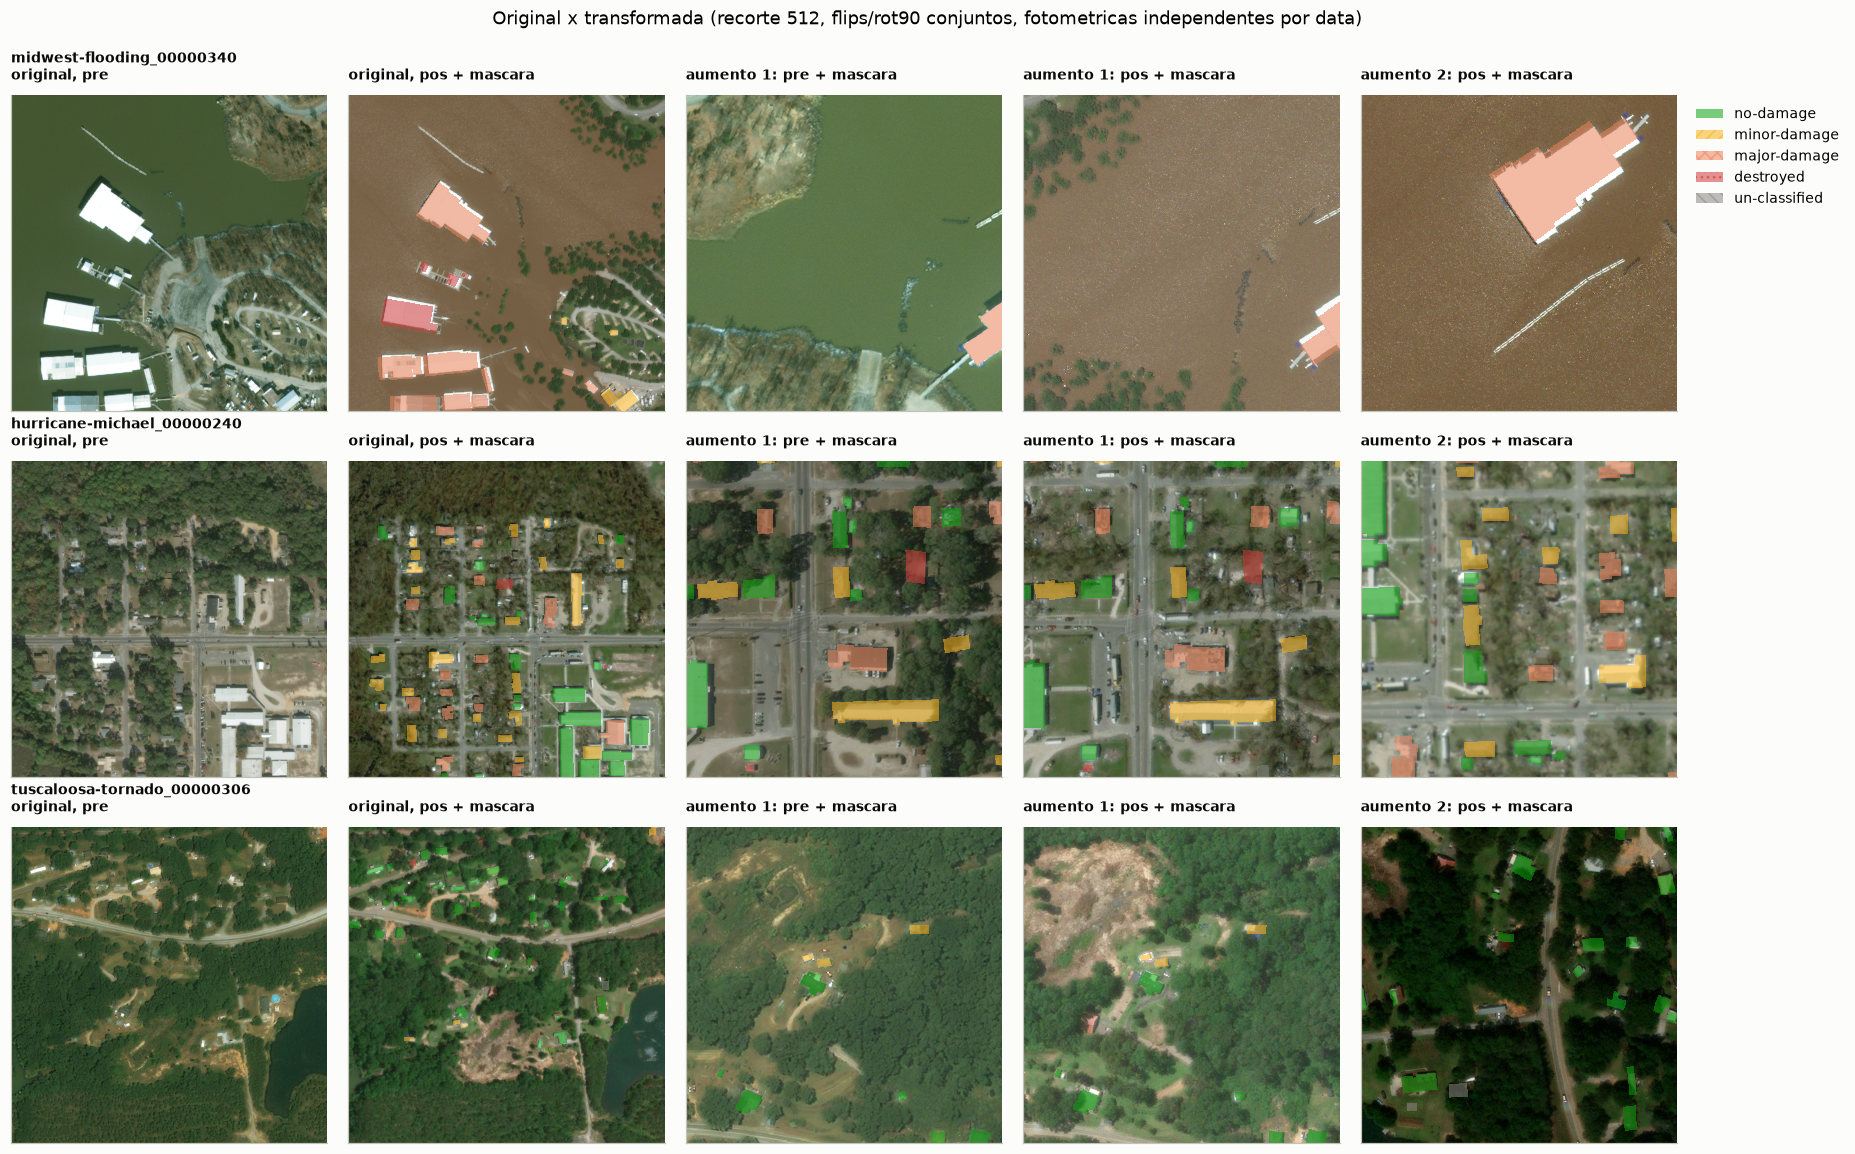

In [7]:
CORES = {1: "no-damage", 2: "minor-damage", 3: "major-damage", 4: "destroyed", 5: "un-classified"}

def sobrepor(ax, img, msk, titulo):
    ax.imshow(img)
    cam = np.zeros(msk.shape + (4,))
    for c, nome in CORES.items():
        cam[msk == c] = to_rgba(V.DAMAGE_COLORS[nome], 0.55)
    ax.imshow(cam, interpolation="nearest")
    ax.set_title(titulo, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

exemplos = treino_df[(treino_df.px_destroyed > 0) & (treino_df.px_minor > 0)].sample(3, random_state=SEED)
fig, ax = plt.subplots(3, 5, figsize=(17, 10.5))
for i, r in enumerate(exemplos.itertuples()):
    pre, post, msk = carregar(r)
    ax[i, 0].imshow(pre); ax[i, 0].set_title(f"{r.scene_id}\noriginal, pre", fontsize=9)
    ax[i, 0].set_xticks([]); ax[i, 0].set_yticks([])
    sobrepor(ax[i, 1], post, msk, "original, pos + mascara")
    pa, qa, ma = aug_tr(pre, post, msk, np.random.default_rng(SEED + i))
    sobrepor(ax[i, 2], pa, ma, "aumento 1: pre + mascara")
    sobrepor(ax[i, 3], qa, ma, "aumento 1: pos + mascara")
    pb, qb, mb = aug_tr(pre, post, msk, np.random.default_rng(SEED + 100 + i))
    sobrepor(ax[i, 4], qb, mb, "aumento 2: pos + mascara")
V.damage_legend(ax[0, 4], loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle("Original x transformada (recorte 512, flips/rot90 conjuntos, fotometricas independentes por data)", y=0.995)
plt.tight_layout()
plt.show()

---
## 6. Smoke test: lotes prontos para o modelo

Um lote de treino (sampler ponderado + aumento) e um de validacao, pelo mesmo
`build_loaders` que `xbd/train.py` usa. Em CPU, sem modelo.

In [8]:
plano = SimpleNamespace(batch_size=4, num_workers=0, pin_memory=False,
                        persistent_workers=False, prefetch_factor=None)
torch.manual_seed(SEED)
dl_tr, dl_va, df_tr, df_va = build_loaders(index, cfg, plano)
print(f"treino {len(df_tr):,} cenas, {len(dl_tr):,} lotes | validacao {len(df_va):,} cenas, {len(dl_va):,} lotes")
for nome, lote in (("treino", next(iter(dl_tr))), ("validacao", next(iter(dl_va)))):
    valores = sorted(torch.unique(lote["mask"]).tolist())
    print(f"{nome:>9}: pre {tuple(lote['pre'].shape)} {lote['pre'].dtype} | pos {tuple(lote['post'].shape)} | "
          f"mascara {tuple(lote['mask'].shape)} {lote['mask'].dtype}, valores {valores}")
    assert lote["pre"].shape == lote["post"].shape == (4, 3, cfg.crop, cfg.crop)
    assert lote["mask"].shape == (4, cfg.crop, cfg.crop) and lote["mask"].dtype == torch.int64
    assert set(valores) <= {0, 1, 2, 3, 4, IGNORE_INDEX}
    assert torch.isfinite(lote["pre"]).all() and torch.isfinite(lote["post"]).all()

treino 8,869 cenas, 2,217 lotes | validacao 933 cenas, 234 lotes


   treino: pre (4, 3, 512, 512) torch.float32 | pos (4, 3, 512, 512) | mascara (4, 512, 512) torch.int64, valores [0, 1, 2, 3, 4]
validacao: pre (4, 3, 512, 512) torch.float32 | pos (4, 3, 512, 512) | mascara (4, 512, 512) torch.int64, valores [0, 1, 2, 4]


---
## 7. Reprodutibilidade

O split nao sorteia nada; a ordem do sampler e as augmentacoes de treino derivam do RNG
do torch, fixado pela seed (`xbd/train.py:semear`).

In [9]:
def primeiro_lote(seed):
    torch.manual_seed(seed)
    dl, *_ = build_loaders(index, cfg, plano)
    return next(iter(dl))

a, b, c = primeiro_lote(SEED), primeiro_lote(SEED), primeiro_lote(7)
mesmo = a["scene_id"] == b["scene_id"] and all(torch.equal(a[k], b[k]) for k in ("pre", "post", "mask"))
outro = a["scene_id"] != c["scene_id"] or not torch.equal(a["pre"], c["pre"])
print(f"mesma seed, mesmo lote (cenas e pixels aumentados): {mesmo}  {a['scene_id']}")
print(f"seed diferente, lote diferente: {outro}  {c['scene_id']}")
assert mesmo and outro

tr42, va42 = montar_splits(index, from_preset("base", seed=42))
tr13, va13 = montar_splits(index, from_preset("base", seed=1337))
assert tr42.scene_id.equals(tr13.scene_id) and va42.scene_id.equals(va13.scene_id)
print("split identico com seeds 42 e 1337 (nao ha sorteio)")

rep = ROOT / "manifestos" / "reproducao.json"
if rep.exists():
    r = json.loads(rep.read_text())
    print(f"\nverificar_reproducao.py ({r['data']}): {r['imagens_e_mascaras_iguais']:,} de "
          f"{r['imagens_e_mascaras_conferidas']:,} imagens/mascaras refeitas dos GeoTIFF batem com o manifesto")

mesma seed, mesmo lote (cenas e pixels aumentados): True  ['hurricane-harvey_00000126', 'hurricane-matthew_00000158', 'hurricane-harvey_00000029', 'nepal-flooding_00000246']
seed diferente, lote diferente: True  ['palu-tsunami_00000002', 'tuscaloosa-tornado_00000039', 'pinery-bushfire_00001052', 'woolsey-fire_00000206']
split identico com seeds 42 e 1337 (nao ha sorteio)

verificar_reproducao.py (2026-10-13 21:34): 33,102 de 33,102 imagens/mascaras refeitas dos GeoTIFF batem com o manifesto


---
## 8. Resumo

| verificacao | resultado |
|---|---|
| manifesto = split do treino (oficial e 5 folds) | conjuntos identicos |
| duplicatas treino x hold/test | 0 (299 copias removidas do treino) |
| duplicatas e grupos entre folds agrupados | 0 |
| eventos em mais de um split oficial | 10, herdado do xView2: use o protocolo agrupado para generalizacao |
| validacao deterministica | sim |
| normalizacao | constantes so do treino |
| mascara acompanha as geometricas | 200 de 200 transformacoes, pixel a pixel |
| lotes | float32 [4,3,512,512] + int64 [4,512,512], valores em {0..4, 255} |
| seed | reproduz split, ordem e aumento |